In [1]:
from dfft.utils.files import get_path
import os
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

In [2]:
def extract_time(d):
    m = re.match(r"(\d{8}_\d{6})", os.path.basename(d))
    return m.group(1) if m else ""

def get_lastest_exp(base_dir):
    exp_dirs = [os.path.join(base_dir, d) for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]
    exp_dirs = sorted(exp_dirs, key=extract_time)
    return exp_dirs[-1]

In [ ]:
name = 'moment-large'
model_configs=["", "-finetuned", "-lora"]

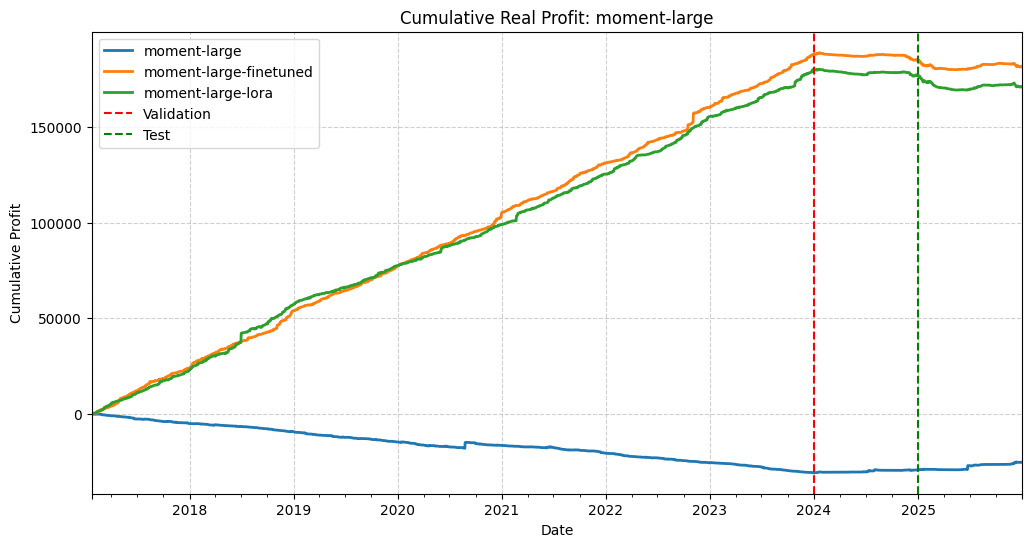

In [ ]:
#Plot Profit over time
all = []
for c in model_configs:
    model = name + c
    base_dir = get_path(f"results\\optimization\\{model}\\NEMA")
    exp_dir = get_lastest_exp(base_dir)
    df = pd.read_parquet(exp_dir + "/opt_results.parquet")
    df.index = pd.date_range(start='2017-01-23', periods=len(df), freq='D')
    df = df['real_profit'].rename(f'{model}')
    all.append(df)

final_df = pd.concat(all, axis= 1)

cumulative_profit = final_df.cumsum()


ax = cumulative_profit.plot(
    kind='line',
    figsize=(12, 6),       
    linewidth=2,           
    title=f'Cumulative Real Profit: {name}',
    ylabel='Cumulative Profit',
    xlabel='Date'
)


ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(title='Model Configuration')   

ax.axvline(
    x = '2024-01-01',
    color='red',
    linestyle='--',
    linewidth=1.5, 
    label='Validation'
)

ax.axvline(
    x = '2025-01-01',
    color='green',
    linestyle='--',
    linewidth=1.5, 
    label='Test'
)

plt.legend()
plt.show()


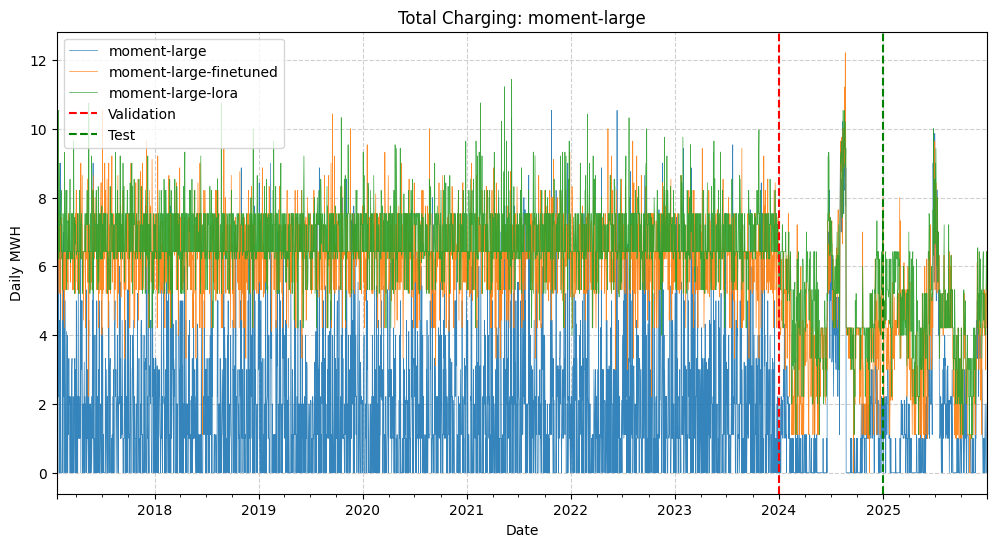

In [20]:
#Plot Charging over time
all = []
for c in model_configs:
    model = name + c
    base_dir = get_path(f"results\\optimization\\{model}\\NEMA")
    exp_dir = get_lastest_exp(base_dir)
    df = pd.read_parquet(exp_dir + "/opt_results.parquet")
    df.index = pd.date_range(start='2017-01-23', periods=len(df), freq='D')
    df = df['pred_charge_schedule'].apply(lambda x: sum(x) if len(x) else 0).rename(f'{model}')
    all.append(df)

final_df = pd.concat(all, axis= 1)


ax = final_df.plot(
    kind='line',
    figsize=(12, 6),       
    linewidth=0.5,
    alpha = 0.9,           
    title=f'Total Charging: {name}',
    ylabel='Daily MWH',
    xlabel='Date'
)

ax.grid(True, linestyle='--', alpha=0.6) 
ax.legend(title='Model Configuration')   

ax.axvline(
    x = '2024-01-01',
    color='red',
    linestyle='--',
    linewidth=1.5, 
    label='Validation'
)

ax.axvline(
    x = '2025-01-01',
    color='green',
    linestyle='--',
    linewidth=1.5, 
    label='Test'
)

plt.legend()

plt.show()